In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import time
from grid_generator import generate_grid
from heuristics import heuristics
from astar import astar

In [2]:
NUM_GRIDS = 20
GRID_ROWS = 20
GRID_COLS = 20
OBSTACLE_PROB = 0.25

print(f"Number of grids: {NUM_GRIDS}")
print(f"Grid dimensions: {GRID_ROWS} x {GRID_COLS}")
print(f"Obstacle probability: {OBSTACLE_PROB}")

Number of grids: 20
Grid dimensions: 20 x 20
Obstacle probability: 0.25


In [ ]:
grid_dataset = []

for i in range(NUM_GRIDS):
    grid, start, goal = generate_grid(rows=GRID_ROWS,cols=GRID_COLS,obstacle_prob=OBSTACLE_PROB,)
    grid_dataset.append({
        "grid": grid,
        "start": start,
        "goal": goal
    })

print(f"Successfully generated {len(grid_dataset)} grids.")

Successfully generated 20 grids.


In [ ]:
results = []

for grid_id, data in enumerate(grid_dataset, start=1):
    grid = data["grid"]
    start = data["start"]
    goal = data["goal"]
    for heuristic_name, heuristic_func in heuristics.items():
        result = astar(grid,start,goal,heuristic_func)

        results.append({
            "Grid": grid_id,
            "Heuristic": heuristic_name,
            "Success": result["success"],
            "Path Length": result["path_length"],
            "Nodes Expanded": result["nodes_expanded"],
            "Execution Time (ms)": result["execution_time"] * 1000,
            "Max Frontier Size": result["max_frontier_size"]
        })

print("All experiments completed!")

All experiments completed!


In [5]:
df = pd.DataFrame(results)

df.head(10)

,Grid,Heuristic,Success,Path Length,Nodes Expanded,Execution Time (ms),Max Frontier Size
0,1,Manhattan,True,10,19,0.1524,13
1,1,Euclidean,True,10,22,0.2795,13
2,1,Chebyshev,True,10,30,0.1583,14
3,2,Manhattan,True,22,75,0.3380,28
4,2,Euclidean,True,22,102,0.7530,25
5,2,Chebyshev,True,22,129,0.5632,29
6,3,Manhattan,True,14,27,0.1696,16
7,3,Euclidean,True,14,37,0.2803,14
8,3,Chebyshev,True,14,51,0.1976,18
9,4,Manhattan,True,22,110,0.5255,30


In [6]:
summary = df.groupby("Heuristic").agg({
    "Execution Time (ms)": ["mean", "std"],
    "Nodes Expanded": ["mean", "std"],
    "Path Length": ["mean", "std"],
    "Max Frontier Size": ["mean", "std"],
    "Success": "mean"
}).round(3)

summary

Execution Time (ms)        Nodes Expanded         Path Length  \
                         mean    std           mean     std        mean   
Heuristic                                                                 
Chebyshev               0.401  0.334          83.95  64.976        17.4   
Euclidean               0.542  0.399          72.35  58.414        17.4   
Manhattan               0.275  0.222          55.00  43.538        17.4   

                 Max Frontier Size        Success  
             std              mean    std    mean  
Heuristic                                          
Chebyshev  9.259             17.60  6.361     1.0  
Euclidean  9.259             19.45  8.988     1.0  
Manhattan  9.259             18.40  8.513     1.0

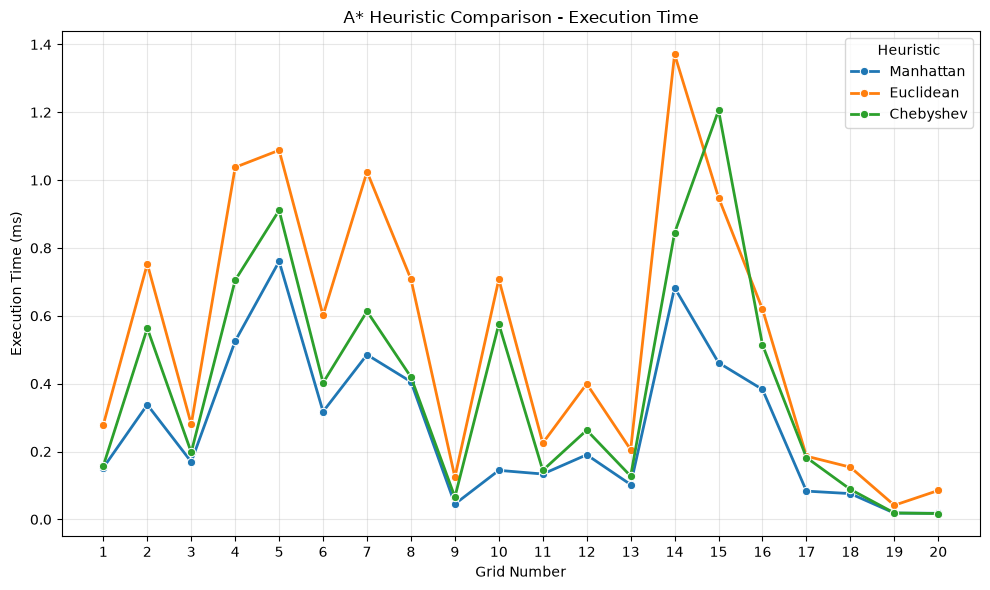

In [7]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df,
    x="Grid",
    y="Execution Time (ms)",
    hue="Heuristic",
    marker="o",
    linewidth=2
)

plt.title("A* Heuristic Comparison - Execution Time")
plt.xlabel("Grid Number")
plt.ylabel("Execution Time (ms)")
plt.xticks(range(1, NUM_GRIDS + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

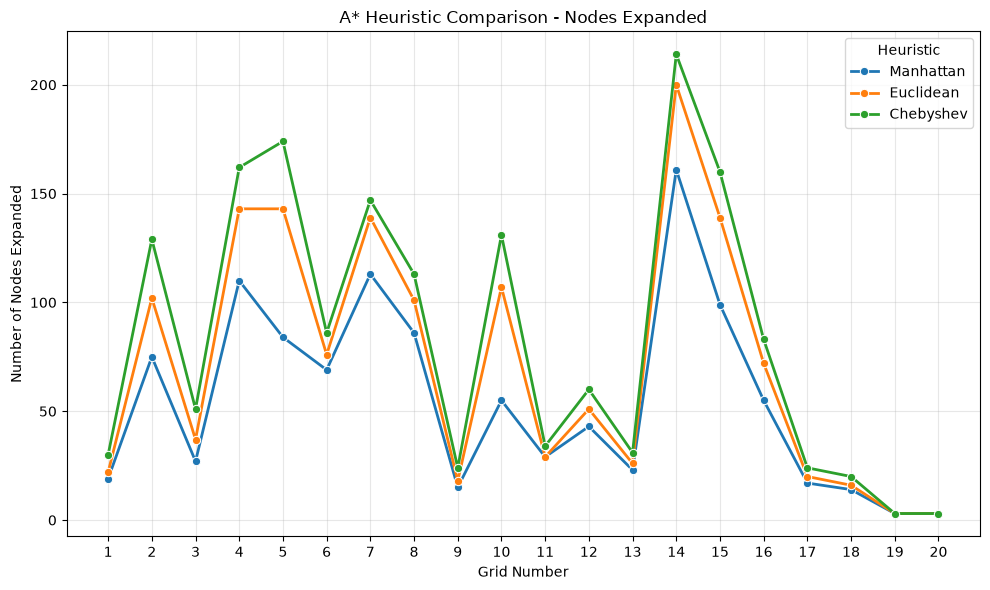

In [8]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df,
    x="Grid",
    y="Nodes Expanded",
    hue="Heuristic",
    marker="o",
    linewidth=2
)

plt.title("A* Heuristic Comparison - Nodes Expanded")
plt.xlabel("Grid Number")
plt.ylabel("Number of Nodes Expanded")
plt.xticks(range(1, NUM_GRIDS + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

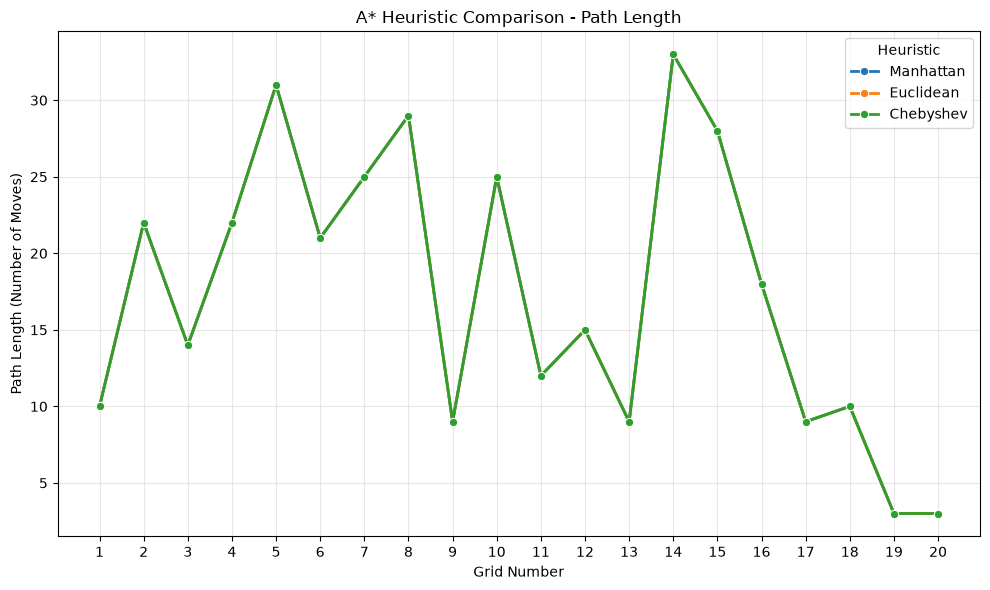

In [9]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df,
    x="Grid",
    y="Path Length",
    hue="Heuristic",
    marker="o",
    linewidth=2
)

plt.title("A* Heuristic Comparison - Path Length")
plt.xlabel("Grid Number")
plt.ylabel("Path Length (Number of Moves)")
plt.xticks(range(1, NUM_GRIDS + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

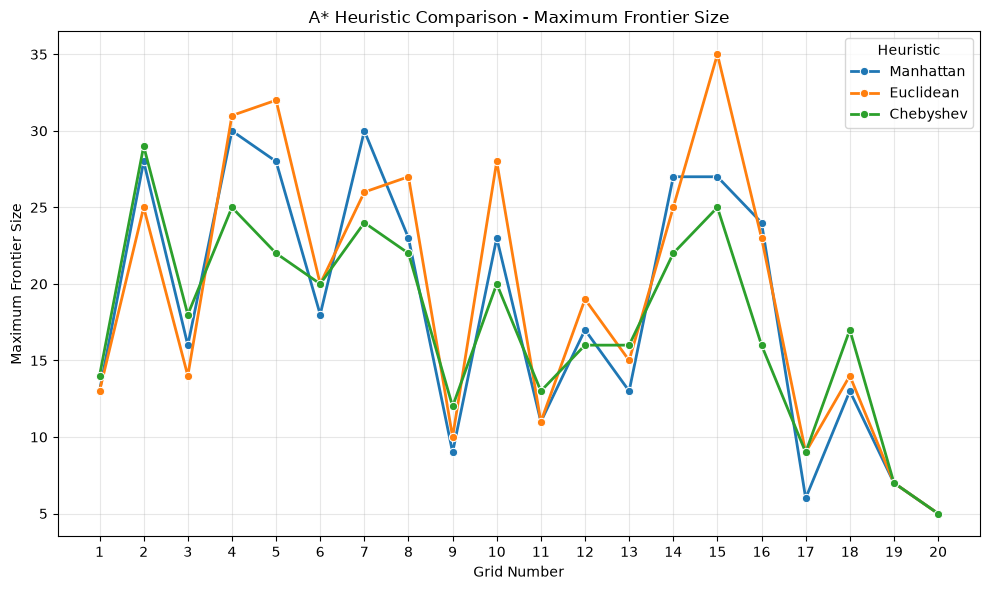

In [10]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df,
    x="Grid",
    y="Max Frontier Size",
    hue="Heuristic",
    marker="o",
    linewidth=2
)

plt.title("A* Heuristic Comparison - Maximum Frontier Size")
plt.xlabel("Grid Number")
plt.ylabel("Maximum Frontier Size")
plt.xticks(range(1, NUM_GRIDS + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

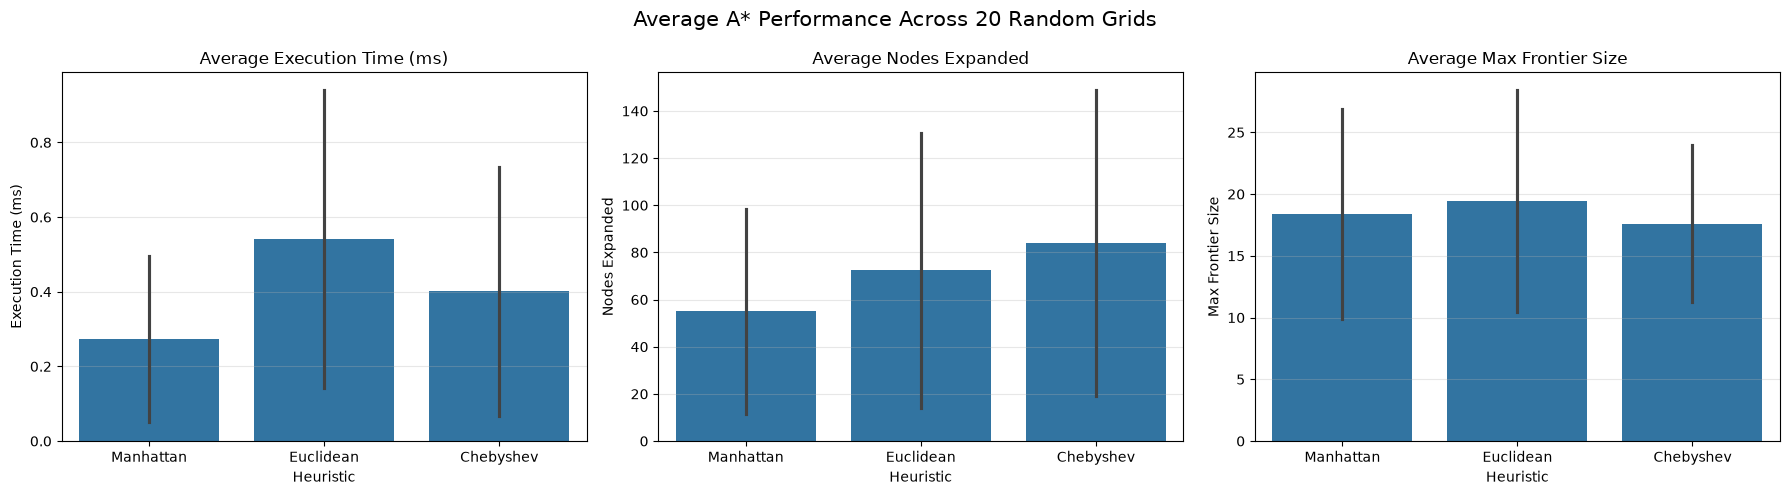

In [11]:
metrics = [
    "Execution Time (ms)",
    "Nodes Expanded",
    "Max Frontier Size"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric in zip(axes, metrics):

    sns.barplot(
        data=df,
        x="Heuristic",
        y=metric,
        estimator="mean",
        errorbar="sd",
        ax=ax
    )

    ax.set_title(f"Average {metric}")
    ax.set_xlabel("Heuristic")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Average A* Performance Across 20 Random Grids",
    fontsize=15
)

plt.tight_layout()
plt.show()